# LIBERO 上で SmolVLA を評価するノートブック

このノートブックは、**LeRobot** の評価環境を Google Colab 上に構築し、  
学習済みポリシー **`HuggingFaceVLA/smolvla_libero`**（LIBERO で追加学習した SmolVLA）を使って **LIBERO** ベンチマーク上で推論・評価を行うためのものです。

## このノートブックで行うこと
- LeRobot と LIBERO の実行に必要なライブラリをインストールする
- Hugging Face へログインして学習済みモデルを利用できるようにする
- 自然言語のタスク指示文を LIBERO のタスク ID に対応付ける
- **SmolVLA** ポリシーでタスクを 1 エピソード評価する
- 評価結果として保存された動画を再生して挙動を確認する

## LIBERO とは
物体操作・空間関係・目標条件などを含む複数のタスク群で構成されており、  
ロボットが異なるタスク間でどの程度知識を転移できるかを調べるのに適しています。
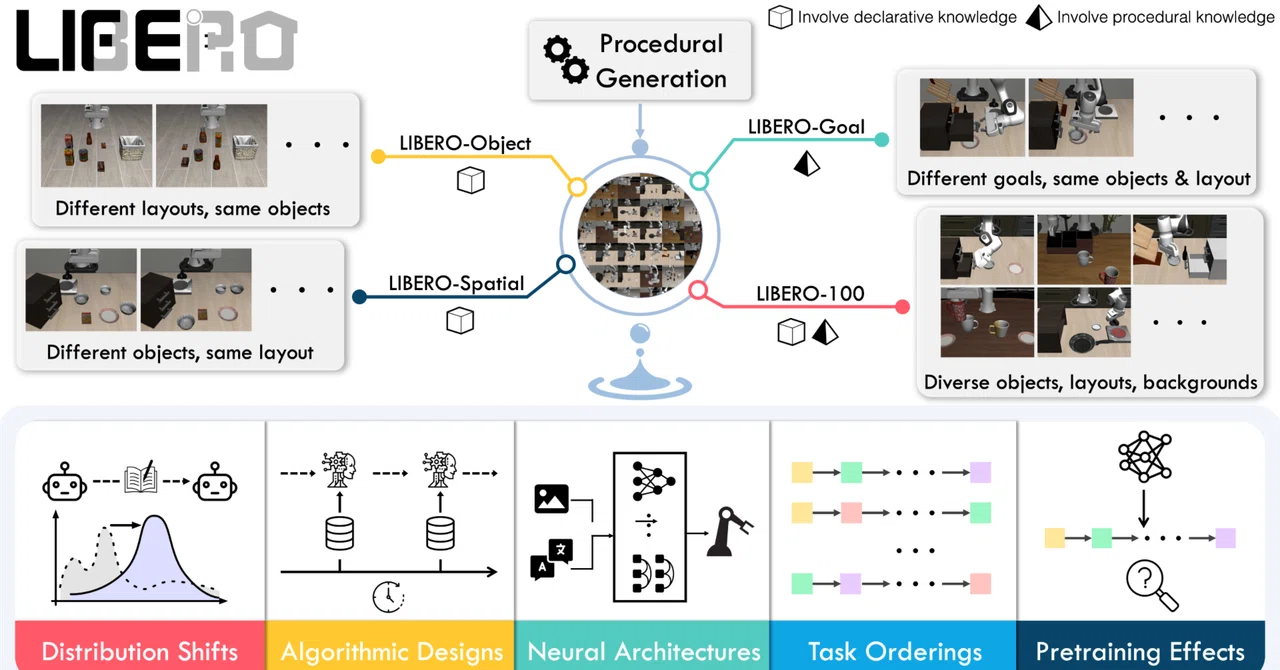


## SmolVLA とは
**SmolVLA** は、画像と言語指示を入力としてロボット行動を生成する、Hugging Face の軽量な  
**Vision-Language-Action (VLA)** モデル（約4.5億パラメータ）です。  
視覚言語モデル（SmolVLM2）と、行動を出す部分（action expert）で構成されています。  
このノートブックで使用している **`HuggingFaceVLA/smolvla_libero`** は、事前学習済みの `lerobot/smolvla_base` を  
LIBERO のデータで追加学習した公開モデルで、LeRobot 上でそのまま LIBERO タスクを実行できます。  
https://huggingface.co/docs/lerobot/smolvla  
https://huggingface.co/HuggingFaceVLA/smolvla_libero

## 実行上の注意
- Colab では **GPU ランタイム** を使用することを推奨します。
- Hugging Face のモデル取得のため、途中で **`login()`** による認証が必要です。
- 評価タスクは `user_instruction` の文を変更することで切り替えられます。
- 実行後、`outputs_smolvla` 以下に評価結果の動画が保存されます。

# 1. 環境構築（依存関係の追加インストール ）

In [13]:
!git clone https://github.com/huggingface/lerobot.git
%cd /content/lerobot

Cloning into 'lerobot'...
remote: Enumerating objects: 57654, done.
remote: Counting objects: 100% (1292/1292), done.
remote: Compressing objects: 100% (565/565), done.
remote: Total 57654 (delta 1001), reused 737 (delta 722), pack-reused 56362 (from 3)
Receiving objects: 100% (57654/57654), 240.44 MiB | 13.86 MiB/s, done.
Resolving deltas: 100% (36367/36367), done.
/content/lerobot


In [14]:
!apt-get update -y
# Colab は Ubuntu 24.04：libgl1-mesa-glx は廃止され，libgl1 と libglx-mesa0 に分かれた
!apt-get install -y libosmesa6 libosmesa6-dev libgl1 libglx-mesa0 libglew2.2 libegl1 ffmpeg

Hit:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:2 https://cli.github.com/packages stable InRelease
Hit:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Reading package lists... Done
W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repo

In [15]:
%%capture
import os
# 描画は GPU（EGL）で行う．osmesa（CPU描画）は非常に遅く，評価が止まったように見える
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

!pip install . --no-deps
!pip install \
    torch torchvision \
    transformers accelerate diffusers \
    datasets huggingface_hub \
    einops opencv-python-headless \
    imageio imageio-ffmpeg \
    "av>=15.0.0,<16.0.0" jsonlines termcolor \
    draccus deepdiff \
    gymnasium \
    pyserial pynput \
    rerun-sdk \
    cmake packaging


!pip install hf-libero robomimic bddl
!pip install sentencepiece timm num2words
# LeRobot（main）は av 15 系が必要（他のバージョンだと AttributeError: module 'av' has no attribute 'option'）
!pip install "av>=15.0.0,<16.0.0"

In [16]:
from huggingface_hub import login
login()

# 実施

In [17]:
import torch
print("cuda:", torch.cuda.is_available())

cuda: True


In [18]:
# @title # LIBERO Evaluation Tasks
# @markdown This notebook evaluates SmolVLA on LIBERO.
# @markdown Each task is specified by a natural language instruction, which is internally mapped to a suite and task ID.
# @markdown
# @markdown ## Supported Suites
# @markdown - **`libero_spatial`**: evaluates changes in spatial relationships
# @markdown - **`libero_object`**: evaluates changes in the target object
# @markdown - **`libero_goal`**: evaluates changes in the goal itself
# @markdown
# @markdown ## `libero_spatial`
# @markdown In this suite, the goal is always to place the **black bowl** on the **plate**, while the initial spatial relationship changes.
# @markdown - **0**: pick up the black bowl between the plate and the ramekin and place it on the plate
# @markdown - **1**: pick up the black bowl next to the ramekin and place it on the plate
# @markdown - **2**: pick up the black bowl from table center and place it on the plate
# @markdown - **3**: pick up the black bowl on the cookie box and place it on the plate
# @markdown - **4**: pick up the black bowl in the top drawer of the wooden cabinet and place it on the plate
# @markdown - **5**: pick up the black bowl on the ramekin and place it on the plate
# @markdown - **6**: pick up the black bowl next to the cookie box and place it on the plate
# @markdown - **7**: pick up the black bowl on the stove and place it on the plate
# @markdown - **8**: pick up the black bowl next to the plate and place it on the plate
# @markdown - **9**: pick up the black bowl on the wooden cabinet and place it on the plate
# @markdown
# @markdown ## `libero_object`
# @markdown In this suite, the goal is always to place the specified object into the **basket**, while the target object changes.
# @markdown - **0**: pick up the alphabet soup and place it in the basket
# @markdown - **1**: pick up the cream cheese and place it in the basket
# @markdown - **2**: pick up the salad dressing and place it in the basket
# @markdown - **3**: pick up the bbq sauce and place it in the basket
# @markdown - **4**: pick up the ketchup and place it in the basket
# @markdown - **5**: pick up the tomato sauce and place it in the basket
# @markdown - **6**: pick up the butter and place it in the basket
# @markdown - **7**: pick up the milk and place it in the basket
# @markdown - **8**: pick up the chocolate pudding and place it in the basket
# @markdown - **9**: pick up the orange juice and place it in the basket
# @markdown
# @markdown ## `libero_goal`
# @markdown In this suite, the goal itself changes across tasks, requiring more diverse behaviors.
# @markdown - **0**: open the middle drawer of the cabinet
# @markdown - **1**: put the bowl on the stove
# @markdown - **2**: put the wine bottle on top of the cabinet
# @markdown - **3**: open the top drawer and put the bowl inside
# @markdown - **4**: put the bowl on top of the cabinet
# @markdown - **5**: push the plate to the front of the stove
# @markdown - **6**: put the cream cheese in the bowl
# @markdown - **7**: turn on the stove
# @markdown - **8**: put the bowl on the plate
# @markdown - **9**: put the wine bottle on the rack
# @markdown


INSTRUCTION_MAP = {
    "libero_spatial": {
        "pick up the black bowl between the plate and the ramekin and place it on the plate": 0,
        "pick up the black bowl next to the ramekin and place it on the plate": 1,
        "pick up the black bowl from table center and place it on the plate": 2,
        "pick up the black bowl on the cookie box and place it on the plate": 3,
        "pick up the black bowl in the top drawer of the wooden cabinet and place it on the plate": 4,
        "pick up the black bowl on the ramekin and place it on the plate": 5,
        "pick up the black bowl next to the cookie box and place it on the plate": 6,
        "pick up the black bowl on the stove and place it on the plate": 7,
        "pick up the black bowl next to the plate and place it on the plate": 8,
        "pick up the black bowl on the wooden cabinet and place it on the plate": 9,
    },
    "libero_object": {
        "pick up the alphabet soup and place it in the basket": 0,
        "pick up the cream cheese and place it in the basket": 1,
        "pick up the salad dressing and place it in the basket": 2,
        "pick up the bbq sauce and place it in the basket": 3,
        "pick up the ketchup and place it in the basket": 4,
        "pick up the tomato sauce and place it in the basket": 5,
        "pick up the butter and place it in the basket": 6,
        "pick up the milk and place it in the basket": 7,
        "pick up the chocolate pudding and place it in the basket": 8,
        "pick up the orange juice and place it in the basket": 9,
    },
    "libero_goal": {
        "open the middle drawer of the cabinet": 0,
        "put the bowl on the stove": 1,
        "put the wine bottle on top of the cabinet": 2,
        "open the top drawer and put the bowl inside": 3,
        "put the bowl on top of the cabinet": 4,
        "push the plate to the front of the stove": 5,
        "put the cream cheese in the bowl": 6,
        "turn on the stove": 7,
        "put the bowl on the plate": 8,
        "put the wine bottle on the rack": 9,
    },
}

libero_spatial（左）、libero_object（中）、libero_goal（右）

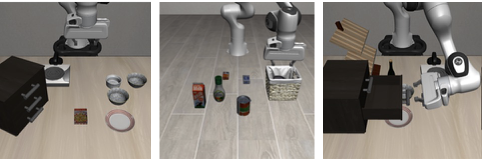

## 使い方
評価したいタスクについて、上の一覧にある指示文のいずれかを `user_instruction` に入力してください。<br>

In [19]:
user_instruction = "pick up the black bowl on the cookie box and place it on the plate"

In [20]:
# @markdown このノートブックでは、LIBERO タスク向けにファインチューニングされた学習済み SmolVLA モデル（HuggingFaceVLA/smolvla_libero）を使用します。<br>
# @markdown 指示文に応じて、対応する suite と task ID が自動的に設定されます。

import difflib

ALL = []
for suite, tasks in INSTRUCTION_MAP.items():
    for k, v in tasks.items():
        ALL.append((k, suite, v))

def match_instruction(text):
    cands = [x[0] for x in ALL]
    best = difflib.get_close_matches(text.lower(), cands, n=1, cutoff=0.2)
    if not best:
        raise ValueError("No match")
    for k, s, tid in ALL:
        if k == best[0]:
            return k, s, tid

matched_instruction, suite, task_id = match_instruction(user_instruction)
task_ids = f"[{task_id}]"

print("input:", user_instruction)
print("matched:", matched_instruction)
print("suite:", suite)
print("task_id:", task_id)

input: pick up the black bowl on the cookie box and place it on the plate
matched: pick up the black bowl on the cookie box and place it on the plate
suite: libero_spatial
task_id: 3


# 評価

初回だけ LIBERO から質問（Y/N）が出ます。**「N」を入力**してください（既定の保存先を使う）。

In [21]:
# SmolVLA（HuggingFaceVLA/smolvla_libero）で評価する
#  - 入力：observation.images.image（正面）・image2（手首）・state（8次元）→ LIBERO 環境の出力名と同じなので名前の変換は不要
#  - 行動：手先の相対移動（6次元）＋グリッパ → control_mode は relative（このモデルの学習時の設定に合わせる）
#  - use_async_envs=false：環境を同じプロセスで動かす（別プロセスだとエラーが表示されずに止まることがある）
#  - n_action_steps：1回の推論で50ステップ分を予測し，そのうち10ステップを実行してから次の推論をする
!MUJOCO_GL=egl PYOPENGL_PLATFORM=egl PYTHONUNBUFFERED=1 lerobot-eval \
  --policy.path=HuggingFaceVLA/smolvla_libero \
  --policy.n_action_steps=10 \
  --env.type=libero \
  --env.task=$suite \
  --env.task_ids=$task_ids \
  --env.control_mode=relative \
  --eval.batch_size=1 \
  --eval.n_episodes=1 \
  --eval.use_async_envs=false \
  --env.episode_length=600 \
  --output_dir=./outputs_smolvla


WARNING 2026-09-28 12:42:02 figs/eval.py:69 No job name provided, using 'libero_smolvla' as job name.
INFO 2026-09-28 12:42:02 bot_eval.py:767 {'env': {'camera_name': 'agentview_image,robot0_eye_in_hand_image',
         'camera_name_mapping': None,
         'control_mode': 'relative',
         'disable_env_checker': True,
         'episode_length': 600,
         'features': {'action': {'shape': (7,),
                                 'type': <FeatureType.ACTION: 'ACTION'>},
                      'pixels/agentview_image': {'shape': (360, 360, 3),
                                                 'type': <FeatureType.VISUAL: 'VISUAL'>},
                      'pixels/robot0_eye_in_hand_image': {'shape': (360,
                                                                    360,
                                                                    3),
                                                          'type': <FeatureType.VISUAL: 'VISUAL'>},
                      'robot_state/eef/mat

# 可視化
movie_path[X] (Xは実行ID)

In [22]:
from pathlib import Path
from IPython.display import Video, display

movie_path = list(Path("./outputs_smolvla").rglob("*.mp4"))

if movie_path:
    display(Video(str(movie_path[0]), embed=True))
else:
    print("No video found")